## 1. Środowisko i rozpakowanie danych
Przeciągnij plik `manul_dataset.zip` na lewy pasek plików w Colabie (ikona folderu), a następnie uruchom poniższą komórkę.


In [ ]:
import os
import zipfile
from google.colab import files
import os
import random
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
# 1. Usunięcie starej bazy
!rm -rf data manul_dataset.zip

# 2. Okienko wyboru pliku
print("Kliknij przycisk poniżej i wskaż plik manul_dataset.zip ze swojego dysku:")
uploaded = files.upload()

# 3. Rozpakowanie
print("\nRozpakowywanie 1050 zdjęć...")
with zipfile.ZipFile("manul_dataset.zip", "r") as zf:
    zf.extractall(".")

# 4. Weryfikacja bazy
DATA_DIR = "data/cropped"
classes = sorted(os.listdir(DATA_DIR))
print(f"\nSukces! Liczba klas: {len(classes)} -> {classes}")
for c in classes:
    cnt = len(os.listdir(os.path.join(DATA_DIR, c)))
    print(f"  - {c:12s}: {cnt} wyciętych zdjęć")

Kliknij przycisk poniżej i wskaż plik manul_dataset.zip ze swojego dysku:


Saving manul_dataset.zip to manul_dataset.zip

Rozpakowywanie 1050 zdjęć...

Sukces! Liczba klas: 5 -> ['bol', 'grusha', 'nagomu', 'primula', 'prinsessa']
  - bol         : 277 wyciętych zdjęć
  - grusha      : 307 wyciętych zdjęć
  - nagomu      : 272 wyciętych zdjęć
  - primula     : 340 wyciętych zdjęć
  - prinsessa   : 37 wyciętych zdjęć


## 2. Podział na zbiory (Train, Val, Test) oraz Augmentacja Danych
Stosujemy stratyfikowany podział: **70% zbiór treningowy**, **15% zbiór walidacyjny**, **15% zbiór testowy**.


In [ ]:
import random
import numpy as np
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Transformacje dla zbioru treningowego (Augmentacja zapobiegająca przeuczeniu)
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Transformacje dla zbioru walidacyjnego i testowego (tylko normalizacja bez augmentacji)
eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

base_dataset = datasets.ImageFolder(DATA_DIR)
class_names = base_dataset.classes
num_classes = len(class_names)
total_samples = len(base_dataset)

from collections import defaultdict
class_indices = defaultdict(list)
for idx, (_, label) in enumerate(base_dataset.samples):
    class_indices[label].append(idx)

train_indices, val_indices, test_indices = [], [], []

for label, indices in class_indices.items():
    random.shuffle(indices)
    n = len(indices)
    n_train = int(0.70 * n)
    n_val = int(0.15 * n)
    train_indices.extend(indices[:n_train])
    val_indices.extend(indices[n_train:n_train + n_val])
    test_indices.extend(indices[n_train + n_val:])

train_dataset = Subset(datasets.ImageFolder(DATA_DIR, transform=train_transforms), train_indices)
val_dataset = Subset(datasets.ImageFolder(DATA_DIR, transform=eval_transforms), val_indices)
test_dataset = Subset(datasets.ImageFolder(DATA_DIR, transform=eval_transforms), test_indices)

BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Liczba próbek ogółem: {total_samples}")
print(f"  - training:  {len(train_indices)} ({len(train_indices)/total_samples:.1%})")
print(f"  - validation: {len(val_indices)} ({len(val_indices)/total_samples:.1%})")
print(f"  - test:     {len(test_indices)} ({len(test_indices)/total_samples:.1%})")


Liczba próbek ogółem: 1233
  - training:  859 (69.7%)
  - validation: 183 (14.8%)
  - test:     191 (15.5%)


### Podgląd przykładowych wykadrowanych manuli


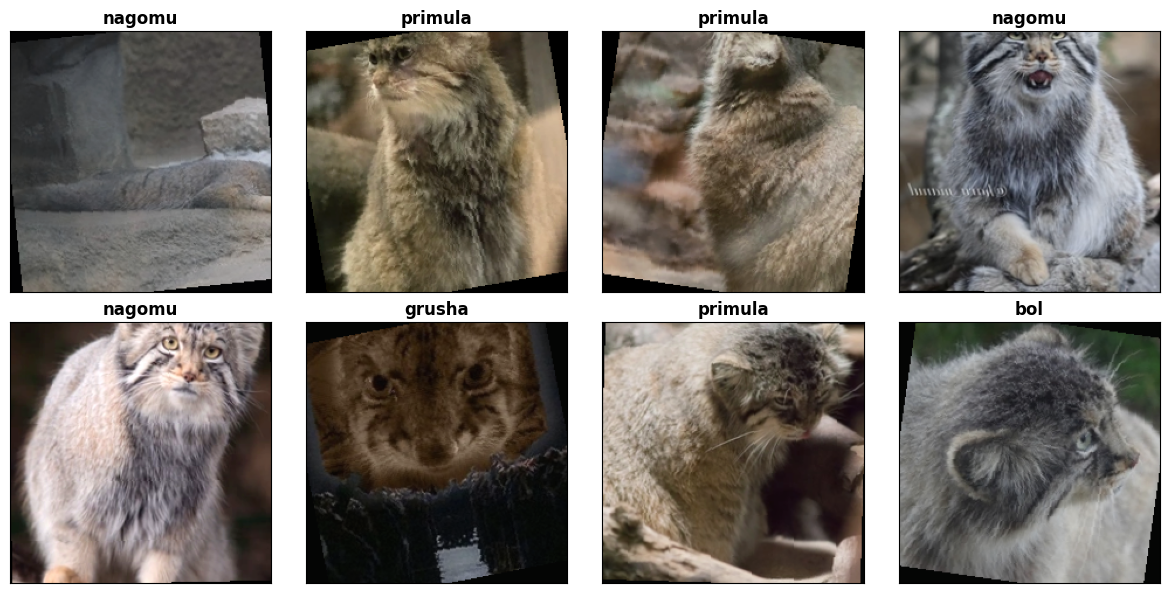

In [ ]:
def imshow_batch(images, labels, classes):
    images = images.numpy().transpose((0, 2, 3, 1))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    images = std * images + mean
    images = np.clip(images, 0, 1)

    fig = plt.figure(figsize=(12, 6))
    for idx in range(min(8, len(images))):
        ax = fig.add_subplot(2, 4, idx + 1, xticks=[], yticks=[])
        plt.imshow(images[idx])
        ax.set_title(classes[labels[idx]], fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

dataiter = iter(train_loader)
images, labels = next(dataiter)
imshow_batch(images, labels, class_names)


## 3. Modułowa Architektura Sieci Neuronowej (`CustomCNN`)
Zgodnie z wymaganiami uczelnianymi, klasa sieci pozwala na pełną parametryzację:
- Liczby bloków konwolucyjnych i filtrów (np. `[32, 64]`, `[32, 64, 128]`, `[32, 64, 128, 256]`)
- Liczby neuronów w warstwie gęstej (`fc_units`)
- Funkcji aktywacji (`ReLU`, `LeakyReLU`, `GELU`)
- Dropoutu i Batch Normalization


In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class CustomCNN(nn.Module):
    def __init__(self, conv_channels=[32, 64, 128], fc_units=256, activation_fn=nn.ReLU, dropout_rate=0.4, num_classes=5):
        super(CustomCNN, self).__init__()

        layers = []
        in_c = 3
        for out_c in conv_channels:
            layers.append(nn.Conv2d(in_c, out_c, kernel_size=3, padding=1))
            layers.append(nn.BatchNorm2d(out_c))
            layers.append(activation_fn())
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            in_c = out_c

        self.features = nn.Sequential(*layers)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        flat_features = in_c * 4 * 4
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(flat_features, fc_units),
            nn.BatchNorm1d(fc_units),
            activation_fn(),
            nn.Dropout(dropout_rate),
            nn.Linear(fc_units, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

# Testowy przebieg w celu weryfikacji wymiarów tensorów
test_model = CustomCNN().to(device)
dummy_input = torch.randn(2, 3, 224, 224).to(device)
dummy_out = test_model(dummy_input)
print(f"Struktura modelu zdefiniowana poprawnie! Kształt wyjścia: {dummy_out.shape}")


Struktura modelu zdefiniowana poprawnie! Kształt wyjścia: torch.Size([2, 5])


## 4. Pętla Trenująca, Early Stopping i Kryteria Błędu (Cross-Entropy + MSE)
- Implementacja algorytmu uczenia się (SGD / Adam)
- Warunek zatrzymania: Early Stopping
- Kryterium pomiaru błędu: Cross-Entropy Loss oraz pomocniczo błąd średniokwadratowy MSE


In [ ]:
import copy
from sklearn.metrics import accuracy_score, f1_score

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=40, patience=8, device=device):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_loss = float("inf")
    patience_counter = 0

    history = {
        "train_loss": [], "val_loss": [],
        "train_mse": [], "val_mse": [],
        "train_acc": [], "val_acc": []
    }

    mse_criterion = nn.MSELoss()

    for epoch in range(1, num_epochs + 1):
        # --- training ---
        model.train()
        running_loss = 0.0
        running_mse = 0.0
        all_preds = []
        all_targets = []

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

            # MSE
            with torch.no_grad():
                probs = F.softmax(outputs, dim=1)
                one_hot_targets = F.one_hot(targets, num_classes=num_classes).float()
                mse = mse_criterion(probs, one_hot_targets)
                running_mse += mse.item() * inputs.size(0)

            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_mse = running_mse / len(train_loader.dataset)
        epoch_train_acc = accuracy_score(all_targets, all_preds)

        # --- FAZA WALIDACYJNA ---
        model.eval()
        running_val_loss = 0.0
        running_val_mse = 0.0
        val_preds = []
        val_targets = []

        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)

                running_val_loss += loss.item() * inputs.size(0)
                probs = F.softmax(outputs, dim=1)
                one_hot_targets = F.one_hot(targets, num_classes=num_classes).float()
                running_val_mse += mse_criterion(probs, one_hot_targets).item() * inputs.size(0)

                _, preds = torch.max(outputs, 1)
                val_preds.extend(preds.cpu().numpy())
                val_targets.extend(targets.cpu().numpy())

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_mse = running_val_mse / len(val_loader.dataset)
        epoch_val_acc = accuracy_score(val_targets, val_preds)

        history["train_loss"].append(epoch_train_loss)
        history["val_loss"].append(epoch_val_loss)
        history["train_mse"].append(epoch_train_mse)
        history["val_mse"].append(epoch_val_mse)
        history["train_acc"].append(epoch_train_acc)
        history["val_acc"].append(epoch_val_acc)

        if epoch % 5 == 0 or epoch == 1:
            print(f"Epoka {epoch:02d}/{num_epochs:02d} | "
                  f"Train Loss: {epoch_train_loss:.4f} (Acc: {epoch_train_acc:.1%}) | "
                  f"Val Loss: {epoch_val_loss:.4f} (Acc: {epoch_val_acc:.1%})")

        # Early Stopping
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"-> Early stopping w epoce {epoch}! Najlepszy Val Loss: {best_val_loss:.4f}")
                break

    model.load_state_dict(best_model_wts)
    return model, history

def evaluate_on_test(model, test_loader, criterion, device=device):
    model.eval()
    running_loss = 0.0
    running_mse = 0.0
    all_preds = []
    all_targets = []
    mse_criterion = nn.MSELoss()

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            running_loss += loss.item() * inputs.size(0)

            probs = F.softmax(outputs, dim=1)
            one_hot_targets = F.one_hot(targets, num_classes=num_classes).float()
            running_mse += mse_criterion(probs, one_hot_targets).item() * inputs.size(0)

            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    test_loss = running_loss / len(test_loader.dataset)
    test_mse = running_mse / len(test_loader.dataset)
    test_acc = accuracy_score(all_targets, all_preds)
    test_f1 = f1_score(all_targets, all_preds, average="weighted")
    return test_loss, test_mse, test_acc, test_f1, all_preds, all_targets


## 5. Seria Eksperymentów
przeprowadzamy serię eksperymentów badających wpływ:
1. **Współczynnika uczenia (*Learning Rate*):** `0.01`, `0.001`, `0.0001`
2. **Funkcji aktywacji:** `ReLU`, `LeakyReLU`, `GELU`
3. **Liczby warstw ukrytych i filtrów splotowych:**
   - Model A (2 bloki): `[32, 64]`
   - Model B (3 bloki): `[32, 64, 128]`
   - Model C (4 bloki): `[32, 64, 128, 256]`
4. **Liczby neuronów w warstwie gęstej (FC):** `128` vs `256` vs `512`


In [ ]:
experiments_results = {}
criterion = nn.CrossEntropyLoss()

# --- EKSPERYMENT 1: Wpływ Learning Rate ---
print("==================================================")
print("EKSPERYMENT 1: Wpływ Learning Rate (lr = 0.01, 0.001, 0.0001)")
print("==================================================")

lr_list = [0.01, 0.001, 0.0001]
for lr in lr_list:
    name = f"LR_{lr}"
    print(f"\n--- Trening: {name} ---")
    model = CustomCNN(conv_channels=[32, 64, 128], fc_units=256, activation_fn=nn.ReLU).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    trained_model, hist = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=35, patience=7)
    test_loss, test_mse, test_acc, test_f1, _, _ = evaluate_on_test(trained_model, test_loader, criterion)

    experiments_results[name] = {
        "history": hist,
        "test_acc": test_acc,
        "test_f1": test_f1,
        "test_loss": test_loss,
        "test_mse": test_mse,
        "model": trained_model
    }
    print(f"Wynik testowy {name}: Acc = {test_acc:.1%}, F1 = {test_f1:.3f}, Loss = {test_loss:.4f}, MSE = {test_mse:.4f}")


EKSPERYMENT 1: Wpływ Learning Rate (lr = 0.01, 0.001, 0.0001)

--- Trening: LR_0.01 ---
Epoka 01/35 | Train Loss: 1.4931 (Acc: 44.8%) | Val Loss: 1.1836 (Acc: 55.2%)
Epoka 05/35 | Train Loss: 1.0824 (Acc: 60.0%) | Val Loss: 1.0195 (Acc: 57.4%)
Epoka 10/35 | Train Loss: 0.9597 (Acc: 64.3%) | Val Loss: 0.9849 (Acc: 59.0%)
-> Early stopping w epoce 14! Najlepszy Val Loss: 0.7998
Wynik testowy LR_0.01: Acc = 69.6%, F1 = 0.688, Loss = 0.8013, MSE = 0.0835

--- Trening: LR_0.001 ---
Epoka 01/35 | Train Loss: 1.2914 (Acc: 48.3%) | Val Loss: 1.0732 (Acc: 58.5%)
Epoka 05/35 | Train Loss: 0.9359 (Acc: 62.5%) | Val Loss: 0.8082 (Acc: 66.1%)
Epoka 10/35 | Train Loss: 0.8404 (Acc: 68.9%) | Val Loss: 0.7545 (Acc: 71.6%)
Epoka 15/35 | Train Loss: 0.7136 (Acc: 73.6%) | Val Loss: 0.7781 (Acc: 68.3%)
Epoka 20/35 | Train Loss: 0.6372 (Acc: 75.4%) | Val Loss: 0.6630 (Acc: 74.3%)
Epoka 25/35 | Train Loss: 0.5901 (Acc: 76.8%) | Val Loss: 0.7413 (Acc: 69.9%)
-> Early stopping w epoce 29! Najlepszy Val Loss: 

In [ ]:
# --- EKSPERYMENT 2: Wpływ Funkcji Aktywacji ---
print("==================================================")
print("EKSPERYMENT 2: Funkcje Aktywacji (ReLU, LeakyReLU, GELU)")
print("==================================================")

activations = {
    "Act_ReLU": nn.ReLU,
    "Act_LeakyReLU": nn.LeakyReLU,
    "Act_GELU": nn.GELU
}

for act_name, act_fn in activations.items():
    if act_name in experiments_results:
        continue
    print(f"\n--- Trening: {act_name} ---")
    model = CustomCNN(conv_channels=[32, 64, 128], fc_units=256, activation_fn=act_fn).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    trained_model, hist = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=35, patience=7)
    test_loss, test_mse, test_acc, test_f1, _, _ = evaluate_on_test(trained_model, test_loader, criterion)

    experiments_results[act_name] = {
        "history": hist,
        "test_acc": test_acc,
        "test_f1": test_f1,
        "test_loss": test_loss,
        "test_mse": test_mse,
        "model": trained_model
    }
    print(f"Wynik testowy {act_name}: Acc = {test_acc:.1%}, F1 = {test_f1:.3f}")


EKSPERYMENT 2: Funkcje Aktywacji (ReLU, LeakyReLU, GELU)

--- Trening: Act_ReLU ---
Epoka 01/35 | Train Loss: 1.2737 (Acc: 48.3%) | Val Loss: 1.0316 (Acc: 59.6%)
Epoka 05/35 | Train Loss: 0.9161 (Acc: 66.4%) | Val Loss: 0.8562 (Acc: 68.3%)
Epoka 10/35 | Train Loss: 0.7995 (Acc: 69.5%) | Val Loss: 0.7039 (Acc: 75.4%)
Epoka 15/35 | Train Loss: 0.7254 (Acc: 74.3%) | Val Loss: 0.7157 (Acc: 72.7%)
Epoka 20/35 | Train Loss: 0.6716 (Acc: 75.4%) | Val Loss: 0.7033 (Acc: 70.5%)
Epoka 25/35 | Train Loss: 0.7024 (Acc: 73.9%) | Val Loss: 0.7379 (Acc: 69.9%)
-> Early stopping w epoce 29! Najlepszy Val Loss: 0.6055
Wynik testowy Act_ReLU: Acc = 72.8%, F1 = 0.716

--- Trening: Act_LeakyReLU ---
Epoka 01/35 | Train Loss: 1.2585 (Acc: 48.9%) | Val Loss: 0.9953 (Acc: 61.7%)
Epoka 05/35 | Train Loss: 0.9405 (Acc: 61.2%) | Val Loss: 0.8893 (Acc: 65.0%)
Epoka 10/35 | Train Loss: 0.7851 (Acc: 70.8%) | Val Loss: 0.7430 (Acc: 73.2%)
Epoka 15/35 | Train Loss: 0.7057 (Acc: 74.3%) | Val Loss: 0.6479 (Acc: 73.8%)

In [ ]:
# --- EKSPERYMENT 3: Głębokość sieci i filtry konwolucyjne ---
print("==================================================")
print("EKSPERYMENT 3: Liczba warstw splotowych i filtrów")
print("==================================================")

depth_configs = {
    "Conv_2_Layers_[32,64]": [32, 64],
    "Conv_3_Layers_[32,64,128]": [32, 64, 128],
    "Conv_4_Layers_[32,64,128,256]": [32, 64, 128, 256]
}

for cfg_name, channels in depth_configs.items():
    if cfg_name in experiments_results:
        continue
    print(f"\n--- Trening: {cfg_name} ---")
    model = CustomCNN(conv_channels=channels, fc_units=256, activation_fn=nn.ReLU).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    trained_model, hist = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=35, patience=7)
    test_loss, test_mse, test_acc, test_f1, _, _ = evaluate_on_test(trained_model, test_loader, criterion)

    experiments_results[cfg_name] = {
        "history": hist,
        "test_acc": test_acc,
        "test_f1": test_f1,
        "test_loss": test_loss,
        "test_mse": test_mse,
        "model": trained_model
    }
    print(f"Wynik testowy {cfg_name}: Acc = {test_acc:.1%}, F1 = {test_f1:.3f}")


## 6. Zestawienie Wyników Eksperymentów (Tabela i Wykresy do Sprawozdania)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

summary_data = []
for name, data in experiments_results.items():
    summary_data.append({
        "Eksperyment / Konfiguracja": name,
        "Test Accuracy": f"{data['test_acc']:.2%}",
        "Test F1-Score": f"{data['test_f1']:.3f}",
        "Test Cross-Entropy Loss": f"{data['test_loss']:.4f}",
        "Test MSE Loss": f"{data['test_mse']:.4f}",
        "Epok przed Early Stop": len(data["history"]["val_loss"])
    })

df_results = pd.DataFrame(summary_data)
display(df_results)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for lr in [0.01, 0.001, 0.0001]:
    key = f"LR_{lr}"
    if key in experiments_results:
        hist = experiments_results[key]["history"]
        axes[0].plot(hist["val_loss"], label=f"Val Loss (lr={lr})")
        axes[1].plot(hist["val_acc"], label=f"Val Acc (lr={lr})")

axes[0].set_title("Wpływ Learning Rate na Funkcję Straty (Val Loss)")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True)
axes[0].legend()

axes[1].set_title("Wpływ Learning Rate na Dokładność (Val Accuracy)")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.savefig("lr_comparison.png", dpi=300)
plt.show()

## 7. Macierz Pomyłek (Confusion Matrix) Najlepszego Modelu
Niezbędna do sprawozdania w celu analizy, które manule są do siebie najbardziej podobne wizualnie.


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# best model
best_exp_name = max(experiments_results, key=lambda k: experiments_results[k]["test_acc"])
best_exp = experiments_results[best_exp_name]
best_model = best_exp["model"]

print(f"Najlepszy model: {best_exp_name} (Dokładność testowa: {best_exp['test_acc']:.1%})")

# ewaluacja i predykcje
_, _, _, _, test_preds, test_targets = evaluate_on_test(best_model, test_loader, criterion)

print("\n--- Raport Klasyfikacji ---")
print(classification_report(test_targets, test_preds, target_names=class_names))

cm = confusion_matrix(test_targets, test_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Macierz Pomyłek - {best_exp_name}", fontsize=14, fontweight="bold")
plt.xlabel("Przewidziany manul", fontsize=12)
plt.ylabel("Rzeczywisty manul", fontsize=12)
plt.tight_layout()
plt.savefig("confusion_matrix_custom_cnn.png", dpi=300)
plt.show()

## 8. Transfer Learning (Fine-Tuning ResNet-50)
Porównanie naszej sieci z modelem pretrenowanym


In [ ]:
from torchvision.models import resnet50, ResNet50_Weights

print("Pobieranie wag pretrenowanego modelu ResNet-50...")
weights = ResNet50_Weights.DEFAULT
resnet = resnet50(weights=weights)

in_features = resnet.fc.in_features
resnet.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.4),
    torch.nn.Linear(in_features, num_classes)
)
resnet = resnet.to(device)

optimizer_resnet = torch.optim.Adam(resnet.parameters(), lr=0.0001)

print("\nRozpoczynam Fine-Tuning ResNet-50...")
resnet_trained, resnet_hist = train_model(
    resnet, train_loader, val_loader, criterion, optimizer_resnet, num_epochs=20, patience=5
)

r_loss, r_mse, r_acc, r_f1, r_preds, r_targets = evaluate_on_test(resnet_trained, test_loader, criterion)

print(f"\n==========================================")
print(f"WYNIKI TRANSFER LEARNING (ResNet-50):")
print(f"  - Test Accuracy: {r_acc:.1%}")
print(f"  - Test F1-Score: {r_f1:.3f}")
print(f"  - Test Cross-Entropy: {r_loss:.4f}")
print(f"  - Test MSE: {r_mse:.4f}")
print(f"==========================================")

# porównanie
print(f"\nPORÓWNANIE DO SPRAWOZDANIA:")
print(f"  Custom CNN ({best_exp_name}): {best_exp['test_acc']:.1%}")
print(f"  ResNet-50 Fine-Tuning:         {r_acc:.1%}")

In [ ]:
!pip install -q ultralytics
import os
from google.colab import files
from PIL import Image
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO
yolo_crop_model = YOLO("yolov8n.pt")
def predict_manul(image_path, model=best_model, use_yolo_crop=True):
    img = Image.open(image_path).convert("RGB")
    cropped_for_display = img
    if use_yolo_crop:
        results = yolo_crop_model(image_path, classes=[15, 16, 21], conf=0.35, verbose=False)
        boxes = results[0].boxes
        if len(boxes) > 0:
            best_idx = torch.argmax(boxes.conf).item()
            x1, y1, x2, y2 = boxes.xyxy[best_idx].tolist()
            img_w, img_h = img.size

            box_w, box_h = x2 - x1, y2 - y1
            cx, cy = (x1 + x2) / 2.0, (y1 + y2) / 2.0
            square_size = min(max(box_w, box_h) * 1.16, min(img_w, img_h))
            half = square_size / 2.0
            c_x1 = max(0, min(img_w - square_size, cx - half))
            c_y1 = max(0, min(img_h - square_size, cy - half))

            img = img.crop((c_x1, c_y1, c_x1 + square_size, c_y1 + square_size))
            cropped_for_display = img
            print("Pomyślnie zlokalizowano manula przy użyciu YOLOv8!")
        else:
            print("YOLO nie wykryło jednoznacznie sylwetki – użyto całego zdjęcia.")


    input_tensor = eval_transforms(img).unsqueeze(0).to(device)


    model.eval()
    with torch.no_grad():
        outputs = model(input_tensor)
        probs = F.softmax(outputs, dim=1).cpu().numpy()[0]

    top_class_idx = np.argmax(probs)
    top_class_name = class_names[top_class_idx]
    top_prob = probs[top_class_idx]


    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    ax1.imshow(cropped_for_display)
    ax1.set_title(f"Rozpoznany manul: {top_class_name.upper()}\n(Pewność: {top_prob:.1%})",
                  fontsize=13, fontweight='bold', color='darkgreen' if top_prob > 0.5 else 'darkorange')
    ax1.axis('off')

    colors = ['darkgreen' if i == top_class_idx else '#4a90e2' for i in range(len(class_names))]
    y_pos = np.arange(len(class_names))
    ax2.barh(y_pos, probs * 100, color=colors)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels([c.upper() for c in class_names], fontsize=11)
    ax2.invert_yaxis()
    ax2.set_xlabel('Prawdopodobieństwo [%]', fontsize=11)
    ax2.set_xlim(0, 100)
    ax2.grid(axis='x', linestyle='--', alpha=0.6)

    for i, v in enumerate(probs * 100):
        ax2.text(v + 1.5, i, f"{v:.1f}%", va='center', fontweight='bold' if i == top_class_idx else 'normal')

    plt.tight_layout()
    plt.show()

print("Wybierz zdjęcie manula z dysku komputera:")
uploaded = files.upload()
for fn in uploaded.keys():
    print(f"\nAnalizuję zdjęcie: {fn}")
    predict_manul(fn)